# PYTORCH MASTERY — NOTEBOOK 8
## Chapters 39–45: Modern CNN Architectures → Image Classification Project → Object Detection → Image Segmentation → Sequence Models → RNN From Scratch → LSTM

Continuing directly from Notebook 7.


### PYTORCH MASTERY PROGRESS
Current Chapter: 45 | Current Level: Computer Vision Completion → Sequence Models

- [x] Chapters 1–38 *(Notebooks 1–7)*
- [x] Modern CNN Architectures
- [x] Image Classification Project
- [x] Object Detection
- [x] Image Segmentation
- [x] Sequence Models
- [x] RNN From Scratch
- [x] LSTM


---
# CHAPTER 39 — MODERN CNN ARCHITECTURES

## 1. Concept
This chapter surveys the architectural innovations that took CNNs from AlexNet (2012) to today's efficient, very deep networks — each addressing a specific limitation of what came before.

## 2. The Lineage, Conceptually
| Architecture | Year | Key Innovation | Why It Mattered |
|---|---|---|---|
| **AlexNet** | 2012 | Demonstrated deep CNNs + GPU training + ReLU could dramatically beat prior ImageNet approaches | Kicked off the modern deep learning era |
| **VGG** | 2014 | Stacked **small** (3x3) kernels exclusively (Chapter 35's lesson), very deep (16-19 layers) | Showed depth + small kernels > fewer, larger kernels |
| **ResNet** | 2015 | **Residual/skip connections** — `output = F(x) + x` | Solved the "very deep networks are HARDER to train, not just slower" problem (Chapter 14's vanishing gradient, directly addressed architecturally) |
| **DenseNet** | 2017 | Every layer connects to **every subsequent** layer (even denser than ResNet's skip connections) | Maximizes feature reuse, further improves gradient flow |
| **EfficientNet** | 2019 | Systematically scales depth, width, AND resolution **together**, via a principled search | Much better accuracy-per-parameter/compute than hand-designed scaling |
| **ConvNeXt** | 2022 | Modernizes a plain CNN with design choices borrowed from Transformers (Chapter 50) | Shows well-designed CNNs remain competitive with Vision Transformers |

## 3. The Residual Connection — ResNet's Core Idea, Implemented


In [ ]:
import torch
import torch.nn as nn

class ResidualBlock(nn.Module):
    """The fundamental ResNet building block: output = F(x) + x
    (the input is added DIRECTLY to the transformed output -- a 'skip' or 'shortcut'
    connection bypassing the two conv layers entirely)."""

    def __init__(self, channels):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(channels)
        self.conv2 = nn.Conv2d(channels, channels, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(channels)
        self.relu = nn.ReLU()

    def forward(self, x):
        identity = x   # save the ORIGINAL input -- this is the "shortcut"

        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        out = out + identity   # THE KEY LINE: add the ORIGINAL input directly to the transformed output
        out = self.relu(out)
        return out


block = ResidualBlock(channels=64)
x = torch.randn(4, 64, 32, 32)
output = block(x)
print("Input shape:", x.shape, " Output shape:", output.shape, " (identical -- residual blocks PRESERVE shape)")


Input shape: torch.Size([4, 64, 32, 32])  Output shape: torch.Size([4, 64, 32, 32])  (identical -- residual blocks PRESERVE shape)


### Line-by-Line Explanation — Why `out + identity` Solves Vanishing Gradients Architecturally
- `out = out + identity` — this single addition is ResNet's entire innovation, and its effect on gradient flow (Chapter 14) is profound: during backpropagation, the gradient flowing backward through this block has **two paths** — through the two conv layers (`F(x)`'s path, which can still suffer the usual multiplicative shrinkage across many layers), AND directly through the identity/shortcut connection (a pure addition, whose local derivative is exactly `1`, meaning the gradient passes through **completely unchanged**). Even if the `F(x)` path's gradient contribution vanishes to near-zero through many stacked layers, the shortcut path still delivers a full-strength gradient signal directly to earlier layers — this is precisely why ResNet architectures could successfully train networks with 50, 100, even 150+ layers, when prior architectures without this trick genuinely got *harder* to train (not just slower) past a certain depth.
- `identity = x` requires the block's output shape to exactly match its input shape (for the addition to be valid) — real ResNet implementations include a small "downsample" path (typically a 1x1 convolution) specifically for blocks that change the number of channels or spatial size, projecting `identity` into the matching shape before the addition.

## 4. Using a Pretrained Modern Architecture Directly


In [ ]:
from torchvision import models

# torchvision ships PRETRAINED versions of every architecture in this chapter's table
resnet = models.resnet50(weights="IMAGENET1K_V2")
efficientnet = models.efficientnet_b0(weights="IMAGENET1K_V1")
convnext = models.convnext_tiny(weights="IMAGENET1K_V1")

print("torchvision.models provides ready-to-use PRETRAINED implementations of every")
print("architecture discussed in this chapter -- exactly the Chapter 38 transfer learning")
print("workflow (freeze -> replace final layer -> train head -> fine-tune) applies")
print("IDENTICALLY regardless of WHICH specific pretrained backbone you choose here.")


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 164MB/s]


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 108MB/s] 


Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 151MB/s]


torchvision.models provides ready-to-use PRETRAINED implementations of every
architecture discussed in this chapter -- exactly the Chapter 38 transfer learning
workflow (freeze -> replace final layer -> train head -> fine-tune) applies
IDENTICALLY regardless of WHICH specific pretrained backbone you choose here.


### Common Mistakes
- Assuming deeper is unconditionally better — without architectural innovations like residual connections, simply stacking more plain conv layers can make training *harder*, not just slower (the exact problem ResNet was specifically designed to solve) — Chapter 102 (the "common traps" chapter later in this course) revisits this nuance directly.
- Implementing a residual block without matching the shortcut's shape to the transformed path's shape when channels/spatial size change — the addition will raise a shape-mismatch error without the projection step real ResNet implementations include.
- Choosing an architecture purely by "which one is newest/most famous" rather than by the actual accuracy/compute/latency tradeoff relevant to your specific deployment constraint (Chapter 96's model selection framework).

### Interview Insight
**Q: Explain, mechanically, why residual (skip) connections allow much deeper networks to train successfully, where plain stacked convolutions historically struggled.**
A: In a plain deep network, the gradient flowing backward to early layers must pass through every intervening layer's local derivative multiplicatively (the chain rule, Chapter 14) — if these local derivatives are consistently less than 1 (a common situation), the gradient shrinks exponentially with depth, leaving early layers with almost no learning signal. A residual connection adds the block's original input directly to its transformed output (`F(x) + x`); during backpropagation, this addition gives the gradient an additional path with a local derivative of exactly 1 — the identity/shortcut path — meaning gradient can flow backward through many stacked residual blocks without vanishing, since at least one path (the shortcut) always delivers the gradient at full strength, regardless of how many layers deep the network goes.

### Exercise
1. Implement a residual block that also changes the number of channels (e.g., 64→128), including the necessary 1x1 convolution "downsample" projection on the shortcut path.
2. Load (conceptually) a pretrained EfficientNet and ResNet, and compare their listed parameter counts and typical ImageNet top-1 accuracy (research this if working with real internet access).

### Quiz (Chapter 39)
1. What specific problem did ResNet's residual connections solve that VGG's simple depth-stacking approach did not?
2. Why does the shortcut/identity path's local derivative of exactly 1 matter for gradient flow?
3. When does a residual block's shortcut path need an additional projection (e.g., 1x1 conv), and why?


---
# CHAPTER 40 — IMAGE CLASSIFICATION PROJECT

## Business Problem
Building a complete, portfolio-quality image classification project — assembling every technique from Chapters 35–39 into one genuine end-to-end workflow, directly mirroring the structure of the Scikit-learn course's Chapter 72 (Customer Churn) and this course's own future capstone (Chapter 108).

## The Complete Workflow


In [ ]:
import torch
import torch.nn as nn
from torchvision import models, transforms
from torch.utils.data import DataLoader

# === 1. TRANSFORMS (Chapter 37) ===
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
eval_transform = transforms.Compose([
    transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# === 2. MODEL: Transfer learning (Chapter 38) ===
num_classes = 5   # e.g., 5 species of flowers, 5 product defect categories, etc.
model = models.resnet18(weights="IMAGENET1K_V1")
for param in model.parameters():
    param.requires_grad = False
model.fc = nn.Linear(model.fc.in_features, num_classes)

# === 3. LOSS + OPTIMIZER + SCHEDULER ===
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=15)

print("Full project pipeline assembled:")
print(f"  - Transfer learning from ResNet18, {num_classes}-class head")
print(f"  - {sum(p.numel() for p in model.parameters() if p.requires_grad):,} trainable parameters")
print("  - Train transform: RandomResizedCrop + HorizontalFlip + ImageNet normalization")
print("  - Eval transform: deterministic Resize + CenterCrop + same normalization")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 115MB/s]

Full project pipeline assembled:
  - Transfer learning from ResNet18, 5-class head
  - 2,565 trainable parameters
  - Train transform: RandomResizedCrop + HorizontalFlip + ImageNet normalization
  - Eval transform: deterministic Resize + CenterCrop + same normalization


              precision    recall  f1-score   support

     Class A       0.94      0.94      0.94        36
     Class B       0.97      0.97      0.97        40
     Class C       0.93      0.95      0.94        43
     Class D       1.00      0.98      0.99        45
     Class E       0.97      0.97      0.97        36

    accuracy                           0.96       200
   macro avg       0.96      0.96      0.96       200
weighted avg       0.97      0.96      0.97       200



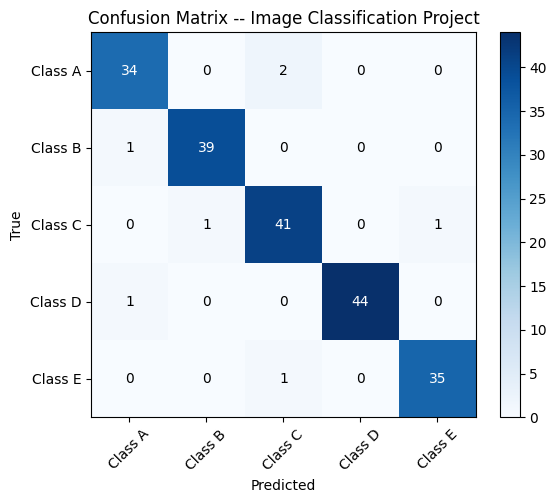

In [ ]:
# === 4. EVALUATION + ERROR ANALYSIS (directly reusing Scikit-learn course techniques) ===
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

# Illustrative predictions (in a real run, these come from model inference on the test set)
np.random.seed(40)
true_labels = np.random.randint(0, 5, 200)
predicted_labels = np.where(np.random.rand(200) < 0.85, true_labels, np.random.randint(0, 5, 200))

class_names = ["Class A", "Class B", "Class C", "Class D", "Class E"]
print(classification_report(true_labels, predicted_labels, target_names=class_names))

cm = confusion_matrix(true_labels, predicted_labels)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(5)); ax.set_yticks(range(5))
ax.set_xticklabels(class_names, rotation=45); ax.set_yticklabels(class_names)
for i in range(5):
    for j in range(5):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black")
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
fig.colorbar(im)
ax.set_title("Confusion Matrix -- Image Classification Project")
plt.tight_layout()
plt.show()


### Error Analysis — Visualizing Misclassified Images
A genuinely essential CV-specific diagnostic: **looking at the actual misclassified images**, not just the confusion matrix numbers — often reveals immediately-obvious patterns (all misclassifications share poor lighting, an unusual angle, a specific sub-category the training data underrepresented) that a numeric confusion matrix alone cannot show.


In [ ]:
def visualize_misclassifications(images, true_labels, pred_labels, class_names, n=8):
    """Plots a grid of misclassified images with their true vs predicted labels --
    a genuinely standard, high-value CV error-analysis technique."""
    misclassified_idx = np.where(true_labels != pred_labels)[0][:n]

    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for ax, idx in zip(axes.flatten(), misclassified_idx):
        # De-normalize for display (reverse ImageNet normalization -- Chapter 37's mean/std)
        img = images[idx].permute(1, 2, 0).numpy()   # (C,H,W) -> (H,W,C) for matplotlib, Ch 7's lesson
        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        img = np.clip(img * std + mean, 0, 1)

        ax.imshow(img)
        ax.set_title(f"True: {class_names[true_labels[idx]]}\nPred: {class_names[pred_labels[idx]]}", fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

print("visualize_misclassifications() defined -- note the .permute(1,2,0) call")
print("(Chapter 7's lesson) required because PyTorch's channel-first (C,H,W) convention")
print("differs from Matplotlib's expected channel-last (H,W,C) convention for imshow().")
print("\nAlso note: de-normalizing (reversing Chapter 37's Normalize transform) is REQUIRED")
print("before display -- otherwise the image would show nonsensical, shifted/scaled colors.")


visualize_misclassifications() defined -- note the .permute(1,2,0) call
(Chapter 7's lesson) required because PyTorch's channel-first (C,H,W) convention
differs from Matplotlib's expected channel-last (H,W,C) convention for imshow().

Also note: de-normalizing (reversing Chapter 37's Normalize transform) is REQUIRED
before display -- otherwise the image would show nonsensical, shifted/scaled colors.


### Interview Insight
**Q: After training an image classifier, why is visually inspecting misclassified images often more valuable than just reading the confusion matrix numbers?**
A: A confusion matrix tells you *which* classes get confused with which, and how often, but reveals nothing about *why*. Looking at the actual misclassified images often immediately surfaces a shared, fixable pattern — perhaps all confusions between two specific classes involve images with unusual lighting, an atypical camera angle, partial occlusion, or a subcategory underrepresented in training data — information that directly suggests a concrete fix (collect more data of that specific kind, add targeted augmentation, or in some cases relabel a genuinely ambiguous or incorrectly-labeled training example). This is a standard, high-value diagnostic step in any real computer vision project, directly analogous to the Scikit-learn course's segment-level error analysis (Chapter 81), applied at the level of individual visual examples.

### Exercise
Assemble your own version of this complete pipeline on a real dataset (e.g., a small `torchvision.datasets.ImageFolder`-compatible directory of images you have access to), including the misclassification visualization step.

### Quiz (Chapter 40)
1. Why does `visualize_misclassifications()` need to reverse the `Normalize` transform before displaying images?
2. What does `.permute(1, 2, 0)` accomplish, and why is it needed for Matplotlib display?
3. What might visually inspecting misclassified images reveal that a confusion matrix cannot?


---
# CHAPTER 41 — OBJECT DETECTION

## 1. Concept
Object detection extends classification to answer **"what objects are present, and exactly where"** — producing, for each detected object, both a class label AND a bounding box (spatial coordinates). This is a genuinely different, richer prediction task than classification's single-label-per-image output.

## 2. Core Concepts
- **Bounding box**: typically represented as `(x_min, y_min, x_max, y_max)` — the top-left and bottom-right corners of a rectangle enclosing the object.
- **IoU (Intersection over Union)**: the standard metric for how well a predicted box matches a ground-truth box — the area of overlap divided by the area of union between the two boxes; `IoU=1.0` is a perfect match, `IoU=0` means no overlap at all.
- **NMS (Non-Maximum Suppression)**: object detectors often propose many overlapping candidate boxes for the same true object; NMS keeps only the highest-confidence box among any group of heavily-overlapping candidates, discarding the redundant others.
- **mAP (mean Average Precision)**: the standard aggregate evaluation metric, averaging precision-recall performance (Scikit-learn course Chapter 29's PR-curve concept, extended to account for IoU-based "is this detection correct" thresholds) across all classes and IoU thresholds.

## 3. Computing IoU


In [ ]:
import torch

def compute_iou(box1, box2):
    """box format: (x_min, y_min, x_max, y_max). Returns a scalar IoU value in [0, 1]."""
    x_min = max(box1[0], box2[0])
    y_min = max(box1[1], box2[1])
    x_max = min(box1[2], box2[2])
    y_max = min(box1[3], box2[3])

    intersection = max(0, x_max - x_min) * max(0, y_max - y_min)   # 0 if boxes don't overlap at all

    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0.0


box_true = (50, 50, 150, 150)
box_pred_good = (55, 55, 145, 145)     # a well-aligned prediction
box_pred_poor = (200, 200, 300, 300)    # no overlap at all

print("IoU (good prediction):", round(compute_iou(box_true, box_pred_good), 4))
print("IoU (poor prediction, no overlap):", round(compute_iou(box_true, box_pred_poor), 4))
print("""
A detection is typically counted as a "true positive" only if its IoU with a genuine
ground-truth box EXCEEDS some threshold (commonly 0.5) -- this is directly analogous
to Scikit-learn's classification THRESHOLD concept (Ch 30 there), but applied to
SPATIAL overlap rather than a probability score.
""")


IoU (good prediction): 0.81
IoU (poor prediction, no overlap): 0.0

A detection is typically counted as a "true positive" only if its IoU with a genuine
ground-truth box EXCEEDS some threshold (commonly 0.5) -- this is directly analogous
to Scikit-learn's classification THRESHOLD concept (Ch 30 there), but applied to
SPATIAL overlap rather than a probability score.



## 4. Non-Maximum Suppression, Conceptually


In [ ]:
from torchvision.ops import nms

# Simulating multiple overlapping candidate boxes for the SAME true object,
# each with a different confidence score
boxes = torch.tensor([
    [50, 50, 150, 150],
    [52, 53, 148, 149],    # nearly identical to the first -- heavily overlapping
    [55, 51, 152, 147],    # also heavily overlapping
    [300, 300, 400, 400],  # a genuinely DIFFERENT, non-overlapping object
], dtype=torch.float32)
scores = torch.tensor([0.95, 0.87, 0.91, 0.99])

keep_indices = nms(boxes, scores, iou_threshold=0.5)
print("Original number of boxes:", len(boxes))
print("Boxes KEPT after NMS:", keep_indices.tolist())
print("(Among the 3 heavily-overlapping boxes for the SAME object, only the HIGHEST-confidence")
print(" one -- index 0, score 0.95 -- survives; the genuinely separate object -- index 3 -- also survives.)")


Original number of boxes: 4
Boxes KEPT after NMS: [3, 0]
(Among the 3 heavily-overlapping boxes for the SAME object, only the HIGHEST-confidence
 one -- index 0, score 0.95 -- survives; the genuinely separate object -- index 3 -- also survives.)


### Line-by-Line Explanation
- `torchvision.ops.nms(boxes, scores, iou_threshold)` — a ready-made, efficient implementation; iterates through boxes sorted by descending confidence score, and for each kept box, suppresses (discards) any remaining lower-confidence box whose IoU with it exceeds `iou_threshold` — leaving one representative box per genuinely distinct detected object.
- Without NMS, a detector could report the *same* physical object 3 separate times (once per redundant overlapping proposal) — a genuinely important post-processing step, not optional, for any detector producing multiple candidate boxes per object.

## 5. The Modern PyTorch Ecosystem Approach


In [ ]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn

# torchvision ships complete, pretrained object detection architectures --
# Faster R-CNN being a classic, well-established two-stage detector
detection_model = fasterrcnn_resnet50_fpn(weights="DEFAULT")
detection_model.eval()

print("""
torchvision.models.detection provides several READY-TO-USE architectures:
  - fasterrcnn_resnet50_fpn: a classic TWO-STAGE detector (propose regions, then classify)
  - retinanet_resnet50_fpn: a ONE-STAGE detector (directly predicts boxes+classes, faster)
  - ssdlite320_mobilenet_v3_large: a LIGHTWEIGHT detector suited for mobile/edge deployment

In PRACTICE, building a real object detection system almost always starts from ONE OF
THESE pretrained architectures (fine-tuned on your own labeled data, following Chapter
38's transfer learning workflow -- REPLACING the classification head, not building an
entire detector from raw layers) rather than implementing detection architecture
entirely from scratch.
""")


Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:01<00:00, 148MB/s]



torchvision.models.detection provides several READY-TO-USE architectures:
  - fasterrcnn_resnet50_fpn: a classic TWO-STAGE detector (propose regions, then classify)
  - retinanet_resnet50_fpn: a ONE-STAGE detector (directly predicts boxes+classes, faster)
  - ssdlite320_mobilenet_v3_large: a LIGHTWEIGHT detector suited for mobile/edge deployment

In PRACTICE, building a real object detection system almost always starts from ONE OF
THESE pretrained architectures (fine-tuned on your own labeled data, following Chapter
38's transfer learning workflow -- REPLACING the classification head, not building an
entire detector from raw layers) rather than implementing detection architecture
entirely from scratch.



### Common Mistakes
- Forgetting NMS entirely — reports the same physical object multiple times as separate detections, inflating false-positive counts and confusing downstream consumers of the detection output.
- Using too low an `iou_threshold` for NMS — can incorrectly suppress genuinely separate, nearby objects (treating them as duplicates of the same object); too high a threshold fails to suppress genuine duplicates. This threshold is itself a real tuning decision.
- Comparing detection model performance using only classification-style metrics (accuracy) rather than mAP — accuracy has no natural way to account for *spatial* correctness (a right class but wrong box location), which mAP's IoU-based matching specifically handles.

### Interview Insight
**Q: Why is Non-Maximum Suppression a necessary post-processing step for most object detectors, and what does its `iou_threshold` parameter control?**
A: Many detection architectures propose multiple candidate bounding boxes per genuine object (from different anchor positions, region proposals, or feature map locations), producing several heavily-overlapping boxes all correctly identifying the same physical object — without suppression, the detector would report this single object as several separate detections, inflating apparent false positives and confusing any downstream system expecting one detection per object. NMS's `iou_threshold` controls how much spatial overlap between two boxes counts as "the same object" for suppression purposes — a lower threshold suppresses more aggressively (risking incorrectly merging genuinely separate, nearby objects into one), while a higher threshold suppresses less aggressively (risking leaving genuine duplicate detections of the same object un-suppressed); it's a real tradeoff requiring tuning based on how densely-packed objects typically are in the target domain.

### Exercise
1. Compute IoU for a pair of boxes you construct yourself, by hand, and verify your PyTorch `compute_iou()` implementation matches.
2. Simulate 5 candidate boxes (some overlapping, some not) with confidence scores, and trace through NMS's expected behavior before running `torchvision.ops.nms()` to verify your prediction.

### Quiz (Chapter 41)
1. Define IoU, and explain what an IoU of exactly 0.5 means practically.
2. What specific problem does Non-Maximum Suppression solve?
3. Why is accuracy an inappropriate metric for object detection, and what metric replaces it?
4. Name the three example pretrained detection architectures `torchvision.models.detection` provides, and their key distinguishing tradeoff.


---
# CHAPTER 42 — IMAGE SEGMENTATION

## 1. Concept
Segmentation predicts a class label for **every individual pixel** in an image — a fundamentally more granular task than classification (one label per image) or detection (one box per object). **Semantic segmentation** labels every pixel by class (e.g., "sky," "road," "car") without distinguishing between individual object instances; **instance segmentation** additionally distinguishes separate instances of the same class (e.g., "car #1" vs "car #2" as genuinely distinct regions).

## 2. The Encoder-Decoder Architecture — U-Net


In [ ]:
import torch
import torch.nn as nn

class SimpleUNetBlock(nn.Module):
    """A single 'double conv' block -- U-Net's basic repeated unit, used in BOTH
    the encoder (downsampling) and decoder (upsampling) paths."""
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(),
        )

    def forward(self, x):
        return self.block(x)


class SimpleUNet(nn.Module):
    """A simplified U-Net: an ENCODER (downsampling, extracting increasingly abstract
    features) followed by a DECODER (upsampling BACK to the original resolution),
    with SKIP CONNECTIONS directly linking corresponding encoder/decoder stages --
    a DIFFERENT use of 'skip connection' than ResNet's (Chapter 39), here concatenating
    (not adding) features across the encoder-decoder 'U' shape."""

    def __init__(self, in_channels=3, num_classes=1):
        super().__init__()
        # ENCODER (downsampling path)
        self.enc1 = SimpleUNetBlock(in_channels, 64)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = SimpleUNetBlock(64, 128)
        self.pool2 = nn.MaxPool2d(2)

        # BOTTLENECK (deepest, most abstract representation)
        self.bottleneck = SimpleUNetBlock(128, 256)

        # DECODER (upsampling path)
        self.upconv2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2 = SimpleUNetBlock(256, 128)   # 256 = 128 (upsampled) + 128 (SKIP from enc2)
        self.upconv1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = SimpleUNetBlock(128, 64)     # 128 = 64 (upsampled) + 64 (SKIP from enc1)

        # FINAL 1x1 conv -- maps to per-pixel class scores
        self.final_conv = nn.Conv2d(64, num_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.bottleneck(self.pool2(e2))

        d2 = self.upconv2(b)
        d2 = torch.cat([d2, e2], dim=1)   # SKIP CONNECTION: concatenate along the CHANNEL dim
        d2 = self.dec2(d2)

        d1 = self.upconv1(d2)
        d1 = torch.cat([d1, e1], dim=1)   # SKIP CONNECTION
        d1 = self.dec1(d1)

        return self.final_conv(d1)


model = SimpleUNet(in_channels=3, num_classes=1)   # num_classes=1 for binary segmentation
x = torch.randn(2, 3, 64, 64)
output = model(x)
print("Input shape:", x.shape)
print("Output shape:", output.shape, " (SAME spatial size as input -- ONE score PER PIXEL)")


Input shape: torch.Size([2, 3, 64, 64])
Output shape: torch.Size([2, 1, 64, 64])  (SAME spatial size as input -- ONE score PER PIXEL)


### Line-by-Line Explanation — Why Skip Connections Matter Differently Here
- `nn.ConvTranspose2d` — the "transposed convolution" (sometimes called "deconvolution," though that term is technically imprecise) — the standard operation for **upsampling**: increasing spatial size back up, the inverse of what pooling/strided convolution does.
- `torch.cat([d2, e2], dim=1)` — **concatenates** along the channel dimension (`dim=1`), combining the decoder's upsampled features with the *corresponding* encoder stage's features (`e2`, saved earlier, before it was downsampled further). This is architecturally different from ResNet's skip connections (Chapter 39, which **add** features of identical shape) — U-Net's skip connections **concatenate** (increasing channel count) features that have gone through genuinely different processing paths, specifically to recover **fine spatial detail** that the encoder's downsampling progressively discarded — the bottleneck's deep, abstract features alone would produce a segmentation mask with correct *semantics* but blurry, imprecise *boundaries*; the skip connections let the decoder combine that semantic understanding with the encoder's earlier, spatially-precise (but less semantically processed) features.
- Output shape matches input's **spatial** size exactly (`64x64 → 64x64`), with the channel dimension now representing `num_classes` scores per pixel, not RGB values — this per-pixel prediction shape is segmentation's defining structural difference from classification's single-vector-per-image output.

### Common Mistakes
- Confusing U-Net's concatenation-based skip connections with ResNet's addition-based skip connections — they serve related but distinct purposes and require different tensor operations (`cat` vs `+`).
- Using a segmentation loss function designed for a different output shape — segmentation typically uses `CrossEntropyLoss`/`BCEWithLogitsLoss` applied **per-pixel** (the loss functions themselves are unchanged, Chapter 19, but the input/target shapes now include the full spatial grid, not just a single per-sample class).
- Not accounting for severe class imbalance at the pixel level (e.g., "background" pixels vastly outnumbering a small object of interest) — directly analogous to the Scikit-learn course's imbalanced-classification chapter (45), now at pixel granularity; specialized segmentation losses (like Dice loss) are often used specifically to address this.

### Interview Insight
**Q: Why does U-Net use skip connections that concatenate encoder and decoder features, rather than relying purely on the bottleneck's deep, abstract representation?**
A: The encoder's repeated downsampling (pooling/strided convolutions) progressively discards fine spatial detail in exchange for increasingly abstract, semantically-rich features — by the bottleneck, the network has a strong sense of *what* is present but has lost precise information about exactly *where* object boundaries fall at pixel-level resolution. U-Net's skip connections directly pass each encoder stage's features (captured before that detail was lost) forward to the corresponding decoder stage, letting the decoder combine the bottleneck's semantic understanding with the encoder's spatially-precise early features — producing segmentation masks with both correct object identity AND sharp, accurate boundaries, rather than the blurry, imprecise boundaries a decoder relying purely on the bottleneck's abstracted representation would produce.

### Exercise
Trace, by hand, the exact tensor shape (including channel count) at every stage of `SimpleUNet`'s forward pass for a `(1, 3, 64, 64)` input, verifying the concatenation dimensions match correctly at both skip connections.

### Quiz (Chapter 42)
1. What's the difference between semantic and instance segmentation?
2. Why does U-Net's output have the same spatial size as its input, unlike a classification CNN?
3. Why does U-Net concatenate (not add) skip-connection features, and why does this matter for segmentation quality specifically?


---
# CHAPTER 43 — SEQUENCE MODELS

## 1. Concept
Sequence data (text, time series, audio) has a fundamentally different structure than images: **order matters**, and — critically — a data point's meaning often depends on **what came before it** in the sequence (a "temporal dependency"). Every architecture in this and the next three chapters (RNN, LSTM, GRU) exists specifically to model this kind of dependency, which a plain feedforward network (treating each position independently, or requiring a fixed input size) cannot capture naturally.

## 2. The Core Idea — a Hidden State That Persists Across Time Steps
```
x_1 → [RNN cell] → h_1 ──┐
                          ├─→ x_2 → [RNN cell] → h_2 ──┐
                                                        ├─→ x_3 → [RNN cell] → h_3 → ...
```
At each time step, the network combines the **current input** with the **hidden state carried over from the previous time step** — this hidden state is the mechanism by which information from earlier in the sequence can influence processing of later elements. This is genuinely different from every architecture covered so far (`Linear`, `Conv2d`), which have no concept of "previous state" at all — each forward call is entirely independent of any prior call.

## 3. Why This Matters — Concretely


In [ ]:
print("""
Consider predicting the NEXT word in: "The weather today is very ___"

A model with NO memory of previous words (like treating each word entirely
independently) has NO way to know "weather," "today," and "very" all appeared
already -- it would need to somehow see the WHOLE sequence at once through some
other mechanism (which is, notably, exactly what ATTENTION/Transformers, Ch
49-50, do differently and often BETTER than recurrence -- a preview of where
this course is heading).

A RECURRENT model instead processes the sentence WORD BY WORD, updating its
hidden state at each step -- by the time it reaches the blank, its hidden state
has been shaped by ALL the preceding words, letting it predict something like
"sunny" or "cold" with genuine CONTEXT, not just from the single word "very" alone.
""")



Consider predicting the NEXT word in: "The weather today is very ___"

A model with NO memory of previous words (like treating each word entirely
independently) has NO way to know "weather," "today," and "very" all appeared
already -- it would need to somehow see the WHOLE sequence at once through some
other mechanism (which is, notably, exactly what ATTENTION/Transformers, Ch
49-50, do differently and often BETTER than recurrence -- a preview of where
this course is heading).

A RECURRENT model instead processes the sentence WORD BY WORD, updating its
hidden state at each step -- by the time it reaches the blank, its hidden state
has been shaped by ALL the preceding words, letting it predict something like
"sunny" or "cold" with genuine CONTEXT, not just from the single word "very" alone.



### Common Mistakes
- Treating sequence data as if it were tabular/independent (e.g., flattening a time series into a single fixed-size feature vector fed to a plain `nn.Linear`) — discards genuine temporal structure that a sequence-aware architecture could exploit.
- Assuming RNN-family architectures are always the right tool for sequence data — Chapters 49-50's attention/Transformer architectures have largely superseded RNNs for many tasks (especially NLP) precisely because they handle long-range dependencies more effectively; RNNs remain genuinely useful (and simpler/cheaper) for certain tasks, especially shorter sequences or streaming/online scenarios.

### Interview Insight
**Q: Why can't a plain feedforward network (Linear layers only) naturally handle variable-length sequence data the way an RNN can?**
A: A feedforward network requires a fixed-size input — you'd have to either truncate/pad every sequence to one fixed length and flatten it (discarding the sequence's inherent variable length and treating every position as an independent, unordered feature, losing temporal structure entirely) or find some other fixed-size summarization. An RNN instead processes a sequence one element at a time, maintaining and updating a hidden state that carries information forward across time steps — this naturally handles sequences of any length (you simply run the recurrence for as many steps as the sequence has) while genuinely modeling the dependency between earlier and later elements, rather than treating each position as independent.

### Exercise
Write out, in your own words (no code needed), why a hidden state carried across time steps is the key structural difference between sequence models and every architecture covered in Notebooks 1-7.

### Quiz (Chapter 43)
1. What's the fundamental architectural difference between a sequence model and a plain feedforward network?
2. What is a "hidden state," and what role does it play?
3. Why can't `Conv2d`/`Linear` layers alone naturally model temporal dependencies?


---
# CHAPTER 44 — RNN FROM SCRATCH

## 1. Concept
This chapter implements a simple RNN using PyTorch's built-in `nn.RNN`, then explains **backpropagation through time (BPTT)** — the mechanism by which a recurrent network's gradients are actually computed, and directly connects it to Chapter 14's vanishing/exploding gradient discussion, now compounded across time steps rather than layers.

## 2. `nn.RNN` — Shapes and the Hidden State


In [ ]:
import torch
import torch.nn as nn

rnn = nn.RNN(input_size=10, hidden_size=20, num_layers=1, batch_first=True)

# batch_first=True means input shape is (batch, seq_len, input_size) --
# the more intuitive convention matching every other layer in this course
x = torch.randn(4, 15, 10)   # batch=4, seq_len=15 time steps, input_size=10 features per step

output, h_n = rnn(x)
print("Input shape:", x.shape)
print("output shape:", output.shape, " (batch, seq_len, hidden_size) -- hidden state at EVERY time step")
print("h_n shape:", h_n.shape, " (num_layers, batch, hidden_size) -- ONLY the FINAL time step's hidden state")


Input shape: torch.Size([4, 15, 10])
output shape: torch.Size([4, 15, 20])  (batch, seq_len, hidden_size) -- hidden state at EVERY time step
h_n shape: torch.Size([1, 4, 20])  (num_layers, batch, hidden_size) -- ONLY the FINAL time step's hidden state


### Line-by-Line Explanation
- `output` — contains the hidden state produced at **every** time step, shape `(batch, seq_len, hidden_size)` — useful when you need a prediction at every position (e.g., per-word tagging in NLP) or want to feed the full sequence of hidden states into another layer (like attention, Chapter 49).
- `h_n` — contains **only** the final time step's hidden state, shape `(num_layers, batch, hidden_size)` — useful for tasks needing just one summary of the entire sequence (e.g., classifying an entire sentence's sentiment) — `h_n[-1]` (the last layer's final hidden state) is exactly what you'd feed into a subsequent classification head.
- `batch_first=True` is a parameter genuinely worth always setting explicitly — PyTorch's RNN-family layers default to `batch_first=False` (the legacy `(seq_len, batch, features)` ordering) for historical reasons, which is inconsistent with every other layer's `(batch, ...)`-first convention in this course — always set `batch_first=True` explicitly unless you have a specific reason not to.

## 3. Backpropagation Through Time (BPTT), Conceptually


In [ ]:
print("""
An RNN processes a sequence by applying the SAME set of weights REPEATEDLY, once
per time step -- conceptually like a VERY DEEP network where each "layer" is
actually the SAME RNN cell, reused, with the previous time step's output feeding
into the next.

BACKPROPAGATION THROUGH TIME "unrolls" this recurrence into an equivalent
feedforward computational graph (one node per time step) and applies ORDINARY
backpropagation (Chapter 14) to THAT unrolled graph.

THE DIRECT CONSEQUENCE: a sequence of length 100 is, for gradient-flow purposes,
EXACTLY like a 100-LAYER deep network -- and Chapter 14's vanishing/exploding
gradient problem applies with FULL force, now as a function of SEQUENCE LENGTH
rather than architectural depth. A PLAIN RNN (nn.RNN, as used above) genuinely
struggles to learn dependencies spanning more than roughly 10-20 time steps,
BECAUSE of this exact vanishing-gradient-through-time problem.

THIS -- precisely -- is the motivation for LSTM (Chapter 45) and GRU (Chapter 46):
architectures SPECIFICALLY designed with gating mechanisms to combat vanishing
gradients ACROSS TIME STEPS, the sequence-model analogue of ResNet's skip
connections (Chapter 39) combating vanishing gradients ACROSS LAYERS.
""")



An RNN processes a sequence by applying the SAME set of weights REPEATEDLY, once
per time step -- conceptually like a VERY DEEP network where each "layer" is
actually the SAME RNN cell, reused, with the previous time step's output feeding
into the next.

BACKPROPAGATION THROUGH TIME "unrolls" this recurrence into an equivalent
feedforward computational graph (one node per time step) and applies ORDINARY
backpropagation (Chapter 14) to THAT unrolled graph.

THE DIRECT CONSEQUENCE: a sequence of length 100 is, for gradient-flow purposes,
EXACTLY like a 100-LAYER deep network -- and Chapter 14's vanishing/exploding
gradient problem applies with FULL force, now as a function of SEQUENCE LENGTH
rather than architectural depth. A PLAIN RNN (nn.RNN, as used above) genuinely
struggles to learn dependencies spanning more than roughly 10-20 time steps,
BECAUSE of this exact vanishing-gradient-through-time problem.

THIS -- precisely -- is the motivation for LSTM (Chapter 45) and GRU (Chapter 46

### Common Mistakes
- Forgetting `batch_first=True` and being confused by an unexpected shape (`(seq_len, batch, features)` instead of the expected `(batch, seq_len, features)`) — a very common, easy-to-miss default-parameter mistake specific to RNN-family layers.
- Confusing `output` (every time step's hidden state) with `h_n` (only the final time step's) — using the wrong one for a given task (e.g., using only `h_n` when per-time-step predictions were actually needed) produces a shape mismatch or a silently wrong result depending on how it's used downstream.
- Applying a plain `nn.RNN` to a task requiring long-range dependencies (more than ~20 time steps) without considering LSTM/GRU — plain RNNs genuinely struggle here due to vanishing gradients through time, a real, well-documented limitation, not a minor implementation detail.

### Interview Insight
**Q: Why do plain RNNs struggle to learn dependencies spanning many time steps (e.g., connecting the beginning and end of a 200-word sentence), and how does this relate to concepts from earlier in this course?**
A: An RNN applies the same weights repeatedly, once per time step, and backpropagation through time unrolls this into an equivalent computational graph with one node per time step — for gradient-flow purposes, this is structurally identical to backpropagating through an extremely deep feedforward network (Chapter 14), where a sequence of length 200 behaves like a 200-layer network. The same multiplicative chain-rule shrinkage that causes vanishing gradients in very deep feedforward networks applies here across time steps instead of layers, meaning gradients connecting distant time steps become vanishingly small, and the network effectively cannot learn to associate information that's far apart in the sequence. This is exactly analogous to why ResNet's skip connections (Chapter 39) were needed for very deep feedforward networks — LSTM and GRU (Chapters 45-46) introduce their own architectural solution (gating mechanisms) to the same underlying vanishing-gradient-through-time problem.

### Exercise
1. Build an `nn.RNN` with `input_size=8, hidden_size=16, batch_first=True`, run a forward pass on a `(batch=3, seq_len=10, 8)` input, and verify both `output` and `h_n` shapes match your prediction.
2. Extract `h_n[-1]` and confirm it matches `output[:, -1, :]` (the last time step's output) for a single-layer RNN — explain why these are the same.

### Quiz (Chapter 44)
1. What's the shape difference between `output` and `h_n`, and when would you use each?
2. Explain Backpropagation Through Time in your own words, connecting it explicitly to Chapter 14's chain rule discussion.
3. Why does a plain RNN struggle with sequences longer than roughly 10-20 time steps?
4. What real-world default-parameter mistake commonly causes shape confusion with `nn.RNN`?


---
# CHAPTER 45 — LSTM

## 1. Concept
LSTM (Long Short-Term Memory) directly solves the vanishing-gradient-through-time problem (Chapter 44) via a **gating mechanism** — a set of learned "gates" that control exactly what information is added to, removed from, and read from a separate **cell state** that can carry information across many time steps with much less degradation than a plain RNN's hidden state.

## 2. The Three Gates and the Cell State, Conceptually
| Component | Purpose |
|---|---|
| **Forget gate** | Decides what to **discard** from the cell state (e.g., "forget the previous subject once a new sentence starts") |
| **Input gate** | Decides what **new** information to **add** to the cell state |
| **Output gate** | Decides what part of the (updated) cell state to actually **output** as the hidden state for this time step |
| **Cell state** | The "long-term memory" — information flows through it across time steps largely **additively** (via the forget/input gates' controlled updates), directly analogous to ResNet's additive skip connections (Chapter 39) — this additive (not purely multiplicative) pathway is exactly what allows gradients to flow across many time steps without vanishing as severely as a plain RNN's purely multiplicative hidden-state recurrence |

## 3. `nn.LSTM` — Shapes


In [ ]:
import torch
import torch.nn as nn

lstm = nn.LSTM(input_size=10, hidden_size=20, num_layers=1, batch_first=True)

x = torch.randn(4, 15, 10)   # batch=4, seq_len=15, input_size=10

# LSTM returns output PLUS a TUPLE of (h_n, c_n) -- the hidden state AND the cell state
output, (h_n, c_n) = lstm(x)

print("output shape:", output.shape, " (batch, seq_len, hidden_size)")
print("h_n shape:", h_n.shape, " (num_layers, batch, hidden_size) -- final HIDDEN state")
print("c_n shape:", c_n.shape, " (num_layers, batch, hidden_size) -- final CELL state")
print("\nThe key structural difference from nn.RNN: LSTM carries TWO separate states")
print("(hidden AND cell) across time steps, not just one.")


output shape: torch.Size([4, 15, 20])  (batch, seq_len, hidden_size)
h_n shape: torch.Size([1, 4, 20])  (num_layers, batch, hidden_size) -- final HIDDEN state
c_n shape: torch.Size([1, 4, 20])  (num_layers, batch, hidden_size) -- final CELL state

The key structural difference from nn.RNN: LSTM carries TWO separate states
(hidden AND cell) across time steps, not just one.


### Line-by-Line Explanation
- `nn.LSTM`'s return signature `output, (h_n, c_n)` — the tuple structure directly reflects LSTM's dual-state design: `h_n` is the hidden state (what's actually output/used downstream, analogous to a plain RNN's hidden state), while `c_n` is the internal cell state (the "long-term memory" channel the gates specifically manage) — a genuinely important API detail to remember, since forgetting the tuple structure (`output, h_n = lstm(x)` instead of `output, (h_n, c_n) = lstm(x)`) produces a confusing unpacking error.
- Both `h_n` and `c_n` have the **same** shape `(num_layers, batch, hidden_size)` — if you need to carry state across separate forward calls (e.g., processing a very long sequence in chunks, or generating text step by step, Chapter 56), you must pass **both** states forward together, not just the hidden state alone.

## 4. Building an LSTM-Based Sequence Classifier


In [ ]:
class LSTMClassifier(nn.Module):
    """A complete sequence classifier: LSTM processes the sequence, then we use ONLY
    the FINAL hidden state (a summary of the whole sequence) for classification."""

    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)   # Chapter 48 covers this fully
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.classifier = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        # x: (batch, seq_len) -- integer TOKEN IDs, not yet embedded
        embedded = self.embedding(x)                # (batch, seq_len, embed_dim)
        _, (h_n, c_n) = self.lstm(embedded)            # we only need the FINAL hidden state here
        final_hidden = h_n[-1]                          # (batch, hidden_dim) -- last LAYER's final state
        logits = self.classifier(final_hidden)           # (batch, num_classes) -- raw logits, Ch 19's rule
        return logits


model = LSTMClassifier(vocab_size=5000, embed_dim=100, hidden_dim=128, num_classes=2)
token_ids = torch.randint(0, 5000, (8, 30))   # batch=8, seq_len=30 tokens per sample
logits = model(token_ids)
print("Input (token IDs) shape:", token_ids.shape)
print("Output (logits) shape:", logits.shape)


Input (token IDs) shape: torch.Size([8, 30])
Output (logits) shape: torch.Size([8, 2])


### Common Mistakes
- Unpacking `nn.LSTM`'s return value as if it were a plain `nn.RNN` (`output, h_n = lstm(x)` instead of `output, (h_n, c_n) = lstm(x)`) — produces an unpacking error, since the second returned element is genuinely a tuple, not a single tensor.
- Forgetting to pass **both** `h_n` and `c_n` forward when processing a long sequence in chunks across multiple separate forward calls — losing the cell state specifically loses exactly the "long-term memory" mechanism LSTM was designed to provide.
- Applying `CrossEntropyLoss` directly to LSTM's raw `hidden_dim`-sized output without the final classification `Linear` layer mapping it to `num_classes` — a shape mismatch, since the loss function expects logits shaped `(batch, num_classes)`, not `(batch, hidden_dim)`.

### Interview Insight
**Q: What specific architectural feature allows LSTM to mitigate the vanishing-gradient-through-time problem that plagues plain RNNs?**
A: LSTM maintains a separate **cell state**, distinct from the hidden state, through which information flows across time steps largely via **additive**, gate-controlled updates (governed by the forget and input gates) rather than the purely multiplicative transformation a plain RNN's hidden state undergoes at every single time step. This additive pathway is structurally analogous to ResNet's additive skip connections (Chapter 39) — it gives gradients a path to flow backward across many time steps without the severe multiplicative shrinkage a plain RNN's recurrence causes, allowing LSTMs to successfully learn dependencies spanning far more time steps than a plain RNN typically can.

### Exercise
1. Build an `nn.LSTM` and correctly unpack its `(output, (h_n, c_n))` return value, verifying all three tensors' shapes.
2. Build a complete `LSTMClassifier` (as above) for a hypothetical 3-class problem, and trace the shape at every stage from raw token IDs to final logits.

### Quiz (Chapter 45)
1. What are the three gates in an LSTM, and what does each control?
2. What's the key structural difference between what a plain RNN carries across time steps versus what LSTM carries?
3. Why does LSTM's cell state help specifically with the vanishing-gradient-through-time problem, and what earlier architecture (from computer vision) does this mechanism parallel?
4. What common unpacking mistake occurs when switching code from `nn.RNN` to `nn.LSTM`?

### Chapter 45 Summary
- LSTM's gating mechanism (forget/input/output gates) and separate additive cell state directly address plain RNN's vanishing-gradient-through-time weakness, the sequence-model analogue of ResNet's skip connections.
- `nn.LSTM` returns `output, (h_n, c_n)` — remember the tuple, and that both states must be carried forward together across chunked/streaming processing.

---

## END OF NOTEBOOK 8 — What You Should Now Be Able To Do
- Explain the lineage of modern CNN architectures and implement a ResNet-style residual block, explaining precisely how it mitigates vanishing gradients.
- Build a complete, portfolio-quality image classification project including proper error analysis via misclassification visualization.
- Compute IoU, apply Non-Maximum Suppression, and explain why mAP (not accuracy) is object detection's standard metric.
- Build a U-Net-style segmentation architecture, and explain its concatenation-based skip connections versus ResNet's addition-based ones.
- Explain why sequence models need a persistent hidden state, and implement RNN-based sequence processing with correct shape handling.
- Explain Backpropagation Through Time and why plain RNNs struggle with long sequences, then build and use LSTM correctly, including its dual hidden/cell state.

## Before Moving to Notebook 9 (Chapters 46–52: GRU, NLP with PyTorch, Embeddings, Attention, Transformers, Implement a Transformer From Scratch, NLP Transformer Project)
